# CART Decision Tree with the Laptop Purchase Dataset

This notebook builds a **CART (Classification and Regression Tree)** model that predicts whether a customer will buy a laptop based on its specifications and the customer's budget.

Steps covered:
1. Build and explore a small laptop purchase dataset.
2. Encode the text categories as numbers.
3. Train a CART classifier that splits using the Gini index.
4. Evaluate the model with standard metrics.
5. Plot the learned decision tree.
6. Predict outcomes for new customers.

The dataset is deliberately tiny, so treat this as a teaching example, not a production model.

## 1. Load the libraries

pandas handles the tabular data, matplotlib draws the charts, and scikit-learn provides the CART model, encoding and metrics.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree

pd.set_option("display.max_columns", None)
plt.style.use("ggplot")

## 2. Build the laptop purchase data

Each row is one customer looking at one laptop. The target column, `Purchase`, records whether they bought it (**Yes**) or walked away (**No**).

| Feature | Values |
|---|---|
| Budget | Low, Medium, High |
| Processor | Basic, Mid, Pro |
| RAM | 8GB, 16GB |
| Battery | Short, Long |

In [2]:
laptop_records = {
    "Budget": [
        "Low", "Low", "Medium", "High", "High", "Medium",
        "Medium", "Low", "High", "Medium", "High",
        "Low", "Medium", "High", "Low", "Medium"
    ],
    "Processor": [
        "Basic", "Mid", "Mid", "Pro", "Mid", "Basic",
        "Pro", "Pro", "Basic", "Mid", "Pro",
        "Basic", "Mid", "Mid", "Mid", "Basic"
    ],
    "RAM": [
        "8GB", "8GB", "16GB", "16GB", "16GB", "8GB",
        "16GB", "16GB", "8GB", "8GB", "8GB",
        "16GB", "16GB", "8GB", "16GB", "16GB"
    ],
    "Battery": [
        "Short", "Long", "Long", "Long", "Short", "Short",
        "Short", "Long", "Long", "Long", "Short",
        "Long", "Short", "Long", "Short", "Long"
    ],
    "Purchase": [
        "No", "No", "Yes", "Yes", "Yes", "No",
        "Yes", "No", "No", "Yes", "Yes",
        "No", "Yes", "Yes", "Yes", "No"
    ]
}

laptop_df = pd.DataFrame(laptop_records)
laptop_df.head()

,Budget,Processor,RAM,Battery,Purchase
0,Low,Basic,8GB,Short,No
1,Low,Mid,8GB,Long,No
2,Medium,Mid,16GB,Long,Yes
3,High,Pro,16GB,Long,Yes
4,High,Mid,16GB,Short,Yes


In [3]:
num_rows, num_cols = laptop_df.shape
print(f"Total records: {num_rows}")
print(f"Total columns: {num_cols}")
print("\nNull values per column:")
display(laptop_df.isnull().sum().to_frame("Null count"))

print("Purchase outcome counts:")
display(laptop_df["Purchase"].value_counts().rename_axis("Purchase").to_frame("Customers"))

Total records: 16
Total columns: 5

Null values per column:


,Null count
Budget,0
Processor,0
RAM,0
Battery,0
Purchase,0


Purchase outcome counts:


,Customers
Purchase,
Yes,9
No,7


## 3. Check the class balance

A quick bar chart shows how many customers bought versus did not buy. The split is not perfectly even, but both outcomes have enough examples to learn from.

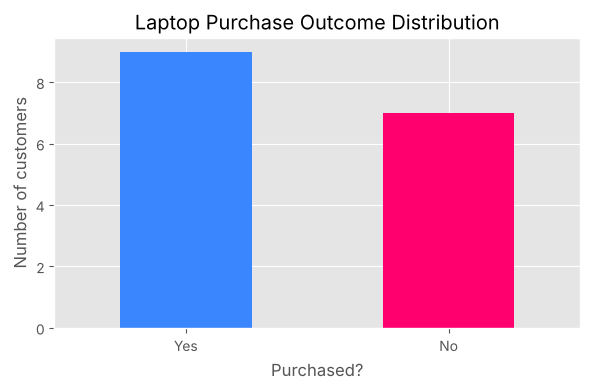

In [4]:
outcome_counts = laptop_df["Purchase"].value_counts().reindex(["Yes", "No"])

fig, axis = plt.subplots(figsize=(6, 4))
outcome_counts.plot(kind="bar", color=["#3a86ff", "#ff006e"], ax=axis)
axis.set_title("Laptop Purchase Outcome Distribution")
axis.set_xlabel("Purchased?")
axis.set_ylabel("Number of customers")
axis.tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.show()

## 4. Work out the first CART split manually

CART looks for the split that produces the purest child groups. Purity is measured with **Gini impurity**:

$$Gini = 1 - \sum_{k} p_k^2$$

where `p_k` is the share of class *k* (`Yes` or `No`) inside a group. For every candidate rule we compute the Gini of the matching and non-matching groups, weight them by size, and compare against the root impurity.

The rule with the **lowest weighted Gini** (equivalently, the **highest impurity drop**) becomes the root split.

In [5]:
label_col = "Purchase"
predictor_cols = ["Budget", "Processor", "RAM", "Battery"]

def gini_impurity(subset):
    """Compute Gini impurity for the label column of a DataFrame subset."""
    if len(subset) == 0:
        return 0.0
    class_shares = subset[label_col].value_counts(normalize=True)
    return 1 - (class_shares ** 2).sum()

root_impurity = gini_impurity(laptop_df)
print(f"Root node Gini impurity: {root_impurity:.4f}")

Root node Gini impurity: 0.4922


In [6]:
candidate_splits = []
total_count = len(laptop_df)

for attribute in predictor_cols:
    for category in sorted(laptop_df[attribute].unique()):
        match_group = laptop_df[laptop_df[attribute] == category]
        rest_group = laptop_df[laptop_df[attribute] != category]

        match_gini = gini_impurity(match_group)
        rest_gini = gini_impurity(rest_group)
        weighted_gini = (
            (len(match_group) / total_count) * match_gini
            + (len(rest_group) / total_count) * rest_gini
        )

        candidate_splits.append({
            "Attribute": attribute,
            "Rule": f"{attribute} == {category}",
            "Match Gini": match_gini,
            "Rest Gini": rest_gini,
            "Weighted Gini": weighted_gini,
            "Impurity Drop": root_impurity - weighted_gini,
        })

splits_table = (
    pd.DataFrame(candidate_splits)
    .sort_values("Weighted Gini")
    .reset_index(drop=True)
)

display(splits_table.round(4))

,Attribute,Rule,Match Gini,Rest Gini,Weighted Gini,Impurity Drop
0,Processor,Processor == Basic,0.0000,0.2975,0.2045,0.2876
1,Processor,Processor == Mid,0.2449,0.4444,0.3571,0.1350
2,Budget,Budget == Low,0.3200,0.3967,0.3727,0.1195
3,Budget,Budget == High,0.3200,0.4959,0.4409,0.0513
4,Battery,Battery == Short,0.4082,0.4938,0.4563,0.0358
5,Battery,Battery == Long,0.4938,0.4082,0.4563,0.0358
6,RAM,RAM == 8GB,0.4898,0.4444,0.4643,0.0279
7,RAM,RAM == 16GB,0.4444,0.4898,0.4643,0.0279
8,Processor,Processor == Pro,0.3750,0.5000,0.4688,0.0234
9,Budget,Budget == Medium,0.4444,0.5000,0.4792,0.0130


In [7]:
top_rule = splits_table.loc[0]

print("Best root split by Gini impurity:")
display(top_rule.to_frame().T)

Best root split by Gini impurity:


,Attribute,Rule,Match Gini,Rest Gini,Weighted Gini,Impurity Drop
0,Processor,Processor == Basic,0.0,0.297521,0.204545,0.287642


## 5. Split and encode the data (no leakage)

Features and target are separated first. The raw rows are then split into train and test sets, and the one-hot encoder is fitted **only on the training features**, so nothing from the test set influences training.

In [8]:
feature_matrix = laptop_df[predictor_cols]
target_vector = laptop_df[label_col]

train_features, test_features, train_labels, test_labels = train_test_split(
    feature_matrix,
    target_vector,
    test_size=0.25,
    random_state=7,
    stratify=target_vector,
)

encoder_pipeline = ColumnTransformer(
    transformers=[
        ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False), predictor_cols)
    ]
)

train_encoded = encoder_pipeline.fit_transform(train_features)
test_encoded = encoder_pipeline.transform(test_features)
onehot_names = encoder_pipeline.get_feature_names_out()

print(f"Training records: {len(train_features)}")
print(f"Test records: {len(test_features)}")
display(pd.DataFrame(train_encoded, columns=onehot_names).head())

Training records: 12
Test records: 4


,onehot__Budget_High,onehot__Budget_Low,onehot__Budget_Medium,onehot__Processor_Basic,onehot__Processor_Mid,onehot__Processor_Pro,onehot__RAM_16GB,onehot__RAM_8GB,onehot__Battery_Long,onehot__Battery_Short
0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
1,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0
2,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0
3,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
4,0.0,1.0,0.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0


## 6. Fit the CART classifier

`criterion="gini"` makes scikit-learn use Gini impurity for splits. Capping the depth at 3 keeps the tree readable and reduces overfitting on such a small dataset.

In [9]:
laptop_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=3,
    random_state=7,
)

laptop_tree.fit(train_encoded, train_labels)
print("CART classifier fitted on training data.")

CART classifier fitted on training data.


## 7. Measure performance

Accuracy gives the share of correct predictions. The classification report breaks results down into precision, recall and F1-score per class.

With only 16 records, these numbers can swing a lot depending on which rows land in the test set, so they are illustrative rather than a dependable performance estimate.

In [10]:
test_predictions = laptop_tree.predict(test_encoded)
test_accuracy = accuracy_score(test_labels, test_predictions)

print(f"Accuracy on test set: {test_accuracy:.2%}\n")
print(classification_report(test_labels, test_predictions, zero_division=0))

Accuracy on test set: 75.00%



              precision    recall  f1-score   support

          No       1.00      0.50      0.67         2
         Yes       0.67      1.00      0.80         2

    accuracy                           0.75         4
   macro avg       0.83      0.75      0.73         4
weighted avg       0.83      0.75      0.73         4



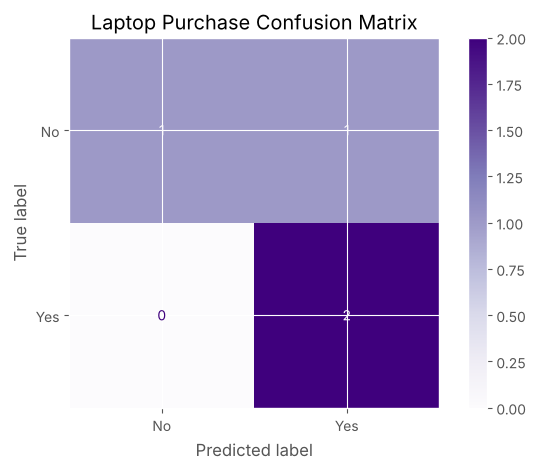

In [11]:
ConfusionMatrixDisplay.from_predictions(
    test_labels,
    test_predictions,
    labels=["No", "Yes"],
    cmap="Purples"
)
plt.title("Laptop Purchase Confusion Matrix")
plt.tight_layout()
plt.show()

## 8. Plot the decision tree

Every internal node holds a yes/no test on one encoded feature; samples go left when the test is true and right otherwise. Leaf nodes show the predicted purchase decision.

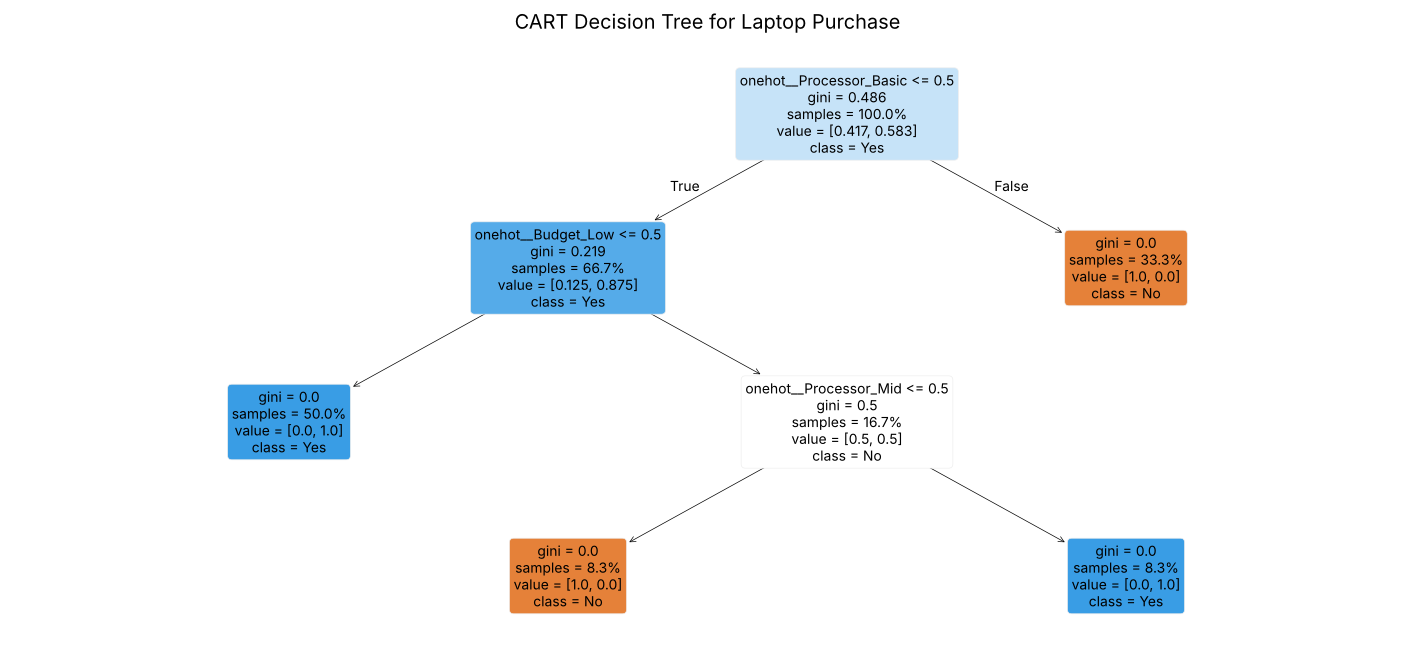

In [12]:
plt.figure(figsize=(18, 8))
plot_tree(
    laptop_tree,
    feature_names=onehot_names,
    class_names=laptop_tree.classes_,
    filled=True,
    rounded=True,
    proportion=True,
    fontsize=10
)
plt.title("CART Decision Tree for Laptop Purchase")
plt.show()

## 9. Predict for new customers

New records must pass through the **same fitted encoder** used for training so their columns line up with what the tree expects.

In [13]:
upcoming_buyers = pd.DataFrame(
    {
        "Budget": ["High", "Low", "Medium"],
        "Processor": ["Pro", "Basic", "Mid"],
        "RAM": ["16GB", "8GB", "16GB"],
        "Battery": ["Long", "Short", "Short"]
    }
)

buyers_encoded = encoder_pipeline.transform(upcoming_buyers)
upcoming_buyers["Predicted Purchase"] = laptop_tree.predict(buyers_encoded)
upcoming_buyers["Probability"] = laptop_tree.predict_proba(buyers_encoded).max(axis=1)
upcoming_buyers["Probability"] = upcoming_buyers["Probability"].apply(lambda p: f"{p:.1%}")
upcoming_buyers

,Budget,Processor,RAM,Battery,Predicted Purchase,Probability
0,High,Pro,16GB,Long,Yes,100.0%
1,Low,Basic,8GB,Short,No,100.0%
2,Medium,Mid,16GB,Short,Yes,100.0%


## 10. Key points

- CART turns training data into a chain of simple if/else rules.
- Gini impurity guides the tree toward splits that separate buyers from non-buyers.
- One-hot encoding converts categorical text features into numeric columns the model can use.
- Limiting tree depth keeps the model interpretable and less prone to overfitting.
- A 16-row dataset is fine for learning the mechanics, but real purchase prediction needs far more data.